# Milestone 3, Section 3: Monitoring

This notebook simulates a production monitoring setup for the deployed bi-encoder
(Milestone 2, Section 4) using real held-out data, and demonstrates the drift and
model-quality computations described in the Section 3 design.

**Stream vs. reference.** We don't have a live extension deployment, so:
- the **reference** distribution is `data/pairs/val.csv` (Jan-Apr 2026) -- the last
  distribution the deployed model was validated against before go-live, i.e. what a
  real monitoring system would compare incoming traffic to.
- the **simulated stream** is `data/pairs/test.csv` (May 2026 onward), replayed in
  chronological order -- a genuine, not fabricated, holdout period, since it was
  never used to pick the model or its threshold (Milestone 2, Section 2.1).

All drift math and plotting live in `src/m3_monitoring.py`, shared the same way
`src/embeddings.py` is shared for Milestone 2.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd

from src.m3_monitoring import (
    load_stream, load_reference, psi, categorical_psi, js_distance, wasserstein,
    score_pairs, rolling_window_metrics, drift_by_window, plot_dashboard, save_individual_panels,
    calibrate_all_thresholds, apply_alerts, sustained,
)

pd.set_option("display.width", 120)

## 1. Investigate first: how much data lands in each window?

The front-page snapshots are collected roughly every 2 days (`DATA_COLLECTION.md`),
so a *daily* window would be mostly empty. Before picking a window size, check what
the real row counts look like per day.

In [2]:
stream_raw = pd.read_csv("data/pairs/test.csv")
ts = pd.to_datetime(stream_raw.timestamp.astype(str), format="%Y%m%d%H%M%S")
print("test.csv spans", ts.min().date(), "to", ts.max().date(), f"({(ts.max()-ts.min()).days} days)")
print()
print("rows per calendar day:")
print(ts.dt.date.value_counts().describe())

test.csv spans 2026-05-01 to 2026-10-09 (161 days)

rows per calendar day:
count    93.000000
mean     26.419355
std      13.423149
min       6.000000
25%      28.000000
50%      28.000000
75%      28.000000
max      56.000000
Name: count, dtype: float64


Daily windows would mostly be empty with the occasional spike -- not usable for a
rolling metric. **We use weekly windows instead**: `load_stream()` buckets by
calendar week, which gives a stable ~24 windows with 40-174 pairs each, enough to
compute a rolling F1 without it being dominated by single-pair noise.

In [3]:
reference = load_reference()
stream = load_stream()  # buckets into weekly windows via the `window` column

print("reference (validation) pairs:", len(reference))
print("stream (test) pairs:", len(stream), "across", stream.window.nunique(), "weekly windows")
window_sizes = stream.groupby("window").size()
window_sizes.describe()

reference (validation) pairs: 2850
stream (test) pairs: 2457 across 24 weekly windows


count     24.000000
mean     102.375000
std       36.418835
min       40.000000
25%       62.000000
50%      112.000000
75%      124.000000
max      174.000000
dtype: float64

## 2. Data-quality monitoring: schema, nulls, distribution drift

We track three signals per window, matching the Section 3.1 design:
- **headline length** (continuous) -- PSI, Jensen-Shannon distance and Wasserstein
  distance, three different ways of asking "how different is this week's headline
  length distribution from validation?"
- **outlet-group mix** (categorical, `major` / `foreign` / `franco` / `local_en` /
  `cdn_unpaid` / `unknown`) -- PSI on category shares.
- **small/local-outlet pair share** -- directly the fairness-relevant quantity named
  in Milestone 2 Section 4.3's "realized small-vs-major-outlet visibility ratio".

Schema/null checks: `test.csv` and `val.csv` have identical columns and zero nulls
in all seven fields (checked once below, not per window, since the schema itself
doesn't change week to week -- only the data does).

In [4]:
required_cols = {"timestamp", "edition", "headline_a", "headline_b", "outlet_a", "outlet_b", "label"}
assert required_cols.issubset(stream.columns), "schema check failed: missing columns"
print("null counts (stream):")
print(stream[list(required_cols)].isna().sum())

null counts (stream):
outlet_a      0
headline_b    0
outlet_b      0
headline_a    0
edition       0
label         0
timestamp     0
dtype: int64


In [5]:
drift = drift_by_window(stream, reference)
drift.round(3)

C:\Users\David\AppData\Local\Temp\ipykernel_31444\1112559695.py:2: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  drift.round(3)


,window,n_pairs,length_psi,length_js,length_wasserstein,group_psi,rare_outlet_share
0,2026-04-27,62,0.131,0.257,3.182,0.286,0.161
1,2026-05-04,145,0.114,0.273,8.289,0.558,0.124
2,2026-05-11,152,0.120,0.178,2.039,0.366,0.283
3,2026-05-18,174,0.064,0.148,2.451,0.392,0.333
4,2026-05-25,90,0.330,0.249,2.440,0.791,0.300
5,2026-06-01,62,0.427,0.295,3.727,1.011,0.000
6,2026-06-08,112,0.066,0.177,1.272,0.638,0.062
7,2026-06-15,62,0.323,0.280,3.782,0.812,0.113
8,2026-06-22,112,0.236,0.215,2.950,0.805,0.241
9,2026-06-29,62,1.532,0.417,6.274,0.834,0.048


## 3. Why is outlet-group PSI elevated almost every week?

At a glance, several weeks sit above the conventional "significant drift" PSI
threshold (0.25) for outlet-group mix. Before treating that as a real finding,
check whether the *aggregate* category shares actually moved that much.

In [6]:
print("validation (reference) outlet-group shares:")
print(reference.group_a.value_counts(normalize=True).round(3))
print()
print("test (stream) outlet-group shares:")
print(stream.group_a.value_counts(normalize=True).round(3))

validation (reference) outlet-group shares:
group_a
major         0.704
foreign       0.223
franco        0.049
cdn_unpaid    0.011
unknown       0.011
local_en      0.002
Name: proportion, dtype: float64

test (stream) outlet-group shares:
group_a
major         0.703
foreign       0.226
franco        0.034
local_en      0.024
cdn_unpaid    0.010
unknown       0.003
Name: proportion, dtype: float64


The aggregate shares barely move (`major` 70.4% -> 70.3%, `foreign` 22.3% -> 22.6%).
What moves a lot in *relative* terms is a rare category: `local_en` goes from 0.2%
to 2.4% of pairs -- a >10x relative jump, even though it's a small absolute count.
PSI's log-ratio term is highly sensitive to exactly this case (small reference share,
any change), and with only 40-174 pairs per week, a single extra `local_en` pair can
swing a window's PSI a lot.

This is the generic 0.1/0.25 PSI convention failing for this project's actual traffic
volume -- it comes from credit-risk model monitoring, not from anything about this
data. Section 5 below fixes this by calibrating thresholds against this project's
own sampling noise instead of borrowing that convention.

## 4. Model-quality monitoring: delayed-truth metrics

We don't have real production telemetry (no deployed extension, no real users), so
there is **no click-through or complaint-rate data to report** -- rather than invent
numbers, we rely only on the metric family we *can* measure honestly: rolling
F1 / ROC-AUC / PR-AUC against the real labels in `test.csv`, standing in for
"delayed truth metrics when labels arrive" (Section 3.1). If this ships for real,
online proxy metrics should be added once real users exist -- not simulated now.

We score every pair with the same deployed bi-encoder and the same 0.724 threshold
used in Milestone 2 (`src/embeddings.py`, `models/minilm_finetuned`).

In [7]:
reference_scores = score_pairs(reference)
stream_scores = score_pairs(stream)

rolling = rolling_window_metrics(stream, stream_scores)
from sklearn.metrics import f1_score, accuracy_score
pred = (stream_scores >= 0.724).astype(int)
print(f"aggregate test F1 over all {len(stream)} pairs:", round(f1_score(stream.label, pred), 3),
      "(accuracy:", round(accuracy_score(stream.label, pred), 3), "-- sanity check vs. Milestone 2's reported 0.906)")
rolling.round(3)

This model was created with Sentence Transformers version 6.2.0, but you're using version 6.1.0. Consider updating to the latest version to avoid potential issues.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

aggregate test F1 over all 2457 pairs: 0.905 (accuracy: 0.912 -- sanity check vs. Milestone 2's reported 0.906)


C:\Users\David\AppData\Local\Temp\ipykernel_31444\2455847151.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  rolling.round(3)


,window,n_pairs,f1,roc_auc,pr_auc,mean_score
0,2026-04-27,62,0.968,1.000,1.000,0.730
1,2026-05-04,145,0.913,0.991,0.991,0.683
2,2026-05-11,152,0.920,0.990,0.990,0.680
3,2026-05-18,174,0.844,0.962,0.958,0.704
4,2026-05-25,90,0.925,0.987,0.987,0.732
5,2026-06-01,62,0.966,1.000,1.000,0.657
6,2026-06-08,112,0.866,0.970,0.966,0.716
7,2026-06-15,62,1.000,1.000,1.000,0.705
8,2026-06-22,112,0.958,0.992,0.989,0.673
9,2026-06-29,62,1.000,1.000,1.000,0.699


Weekly F1 swings much more than the aggregate test F1 reported in Milestone 2
(0.906) -- several weeks dip into the 0.80s, some weeks hit 1.0. That's sampling
noise from small weekly windows (as few as 40 pairs), not necessarily real model
decay. A single week dropping below the 0.90 SLO should not by itself trigger a
rollback -- quantified properly in Section 5 below, instead of asserted.

## 4.5. Two more signals, now that Section 2 has landed: abstention/coverage and sanitizer trigger rate

Section 2's robustness work added two real components to the deployed pipeline that
this monitoring design didn't originally account for:
- a **calibrated abstention band** (Platt-scaled probability near 0.5) -- pairs the
  model isn't confident about are left ungrouped, and the extension keeps Google's
  original card instead of guessing;
- a **sanitizer** that strips invisible characters, folds homoglyphs back to Latin
  letters, and removes known boilerplate prefixes like "LIVE:" before scoring.

Both are implementable right now without new infrastructure: `src/robustness.py`
(merged to `main`) already has `sanitize()`, `Pipeline` (threshold + Platt
calibration) and `abstain_band()` from Section 2's own work. We reuse them directly
rather than re-deriving a second, possibly-inconsistent version.

In [8]:
from src.m3_monitoring import sanitizer_rate_by_window, fit_v1_pipeline, coverage_by_window
from src.robustness import abstain_band

pipe = fit_v1_pipeline(reference)
print("fitted threshold:", round(pipe.threshold, 4), "(Milestone 2's is 0.724 -- sanity check)")

band = abstain_band(pipe, reference, coverage=0.9)
print("abstention band (calibrated probability):", tuple(round(b, 3) for b in band))

coverage_tbl = coverage_by_window(stream, pipe, band)
sanitizer_tbl = sanitizer_rate_by_window(stream)

print()
print("mean coverage across all windows:", round(coverage_tbl.coverage.mean(), 3),
      "(Section 2 reports 91.9% on clean validation -- consistent)")
coverage_tbl.round(3)

This model was created with Sentence Transformers version 6.2.0, but you're using version 6.1.0. Consider updating to the latest version to avoid potential issues.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

fitted threshold: 0.7244 (Milestone 2's is 0.724 -- sanity check)


abstention band (calibrated probability): (0.307, 0.608)



mean coverage across all windows: 0.92 (Section 2 reports 91.9% on clean validation -- consistent)


C:\Users\David\AppData\Local\Temp\ipykernel_31444\2447083119.py:16: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  coverage_tbl.round(3)


,coverage,selective_f1,window,n_pairs
0,0.935,0.984,2026-04-27,62
1,0.966,0.933,2026-05-04,145
2,0.941,0.952,2026-05-11,152
3,0.874,0.904,2026-05-18,174
4,0.900,0.972,2026-05-25,90
5,0.952,0.981,2026-06-01,62
6,0.857,0.964,2026-06-08,112
7,0.984,1.000,2026-06-15,62
8,0.946,0.966,2026-06-22,112
9,1.000,1.000,2026-06-29,62


In [9]:
sanitizer_tbl.round(3)

C:\Users\David\AppData\Local\Temp\ipykernel_31444\3270394992.py:1: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  sanitizer_tbl.round(3)


,window,n_pairs,sanitizer_trigger_rate
0,2026-04-27,62,0.024
1,2026-05-04,145,0.072
2,2026-05-11,152,0.069
3,2026-05-18,174,0.080
4,2026-05-25,90,0.000
5,2026-06-01,62,0.056
6,2026-06-08,112,0.000
7,2026-06-15,62,0.000
8,2026-06-22,112,0.031
9,2026-06-29,62,0.000


Mean coverage lands within a point of Section 2's own reported 91.9% clean-validation
figure -- a useful cross-check that this notebook's `Pipeline` (threshold + Platt fit)
really does reproduce Section 2's, not a divergent reimplementation. The sanitizer
trigger rate is low and fairly flat here, which is expected: this is real historical
traffic with no attack in it, so this run establishes what the *normal* baseline looks
like, for the calibration below to compare future windows against.

## 5. Calibrating thresholds against this project's own noise floor

Recommendation: don't alert on generic industry thresholds (0.1/0.25 PSI, a fixed
0.90 F1 floor) when they were never validated against this project's own data. We
calibrate each one instead, by repeatedly resampling the **reference** data under a
null hypothesis of "no real drift" and seeing how much each metric swings on its own:

- **length PSI / group PSI**: split `val.csv` into two random halves, repeatedly,
  and compute PSI between the halves. Both halves come from the same distribution
  by construction, so this is a pure noise distribution -- the alert threshold is
  its 95th percentile, not a borrowed number.
- **F1 floor / rare-outlet-share band / coverage floor / sanitizer ceiling**: draw
  random windows the *same size* as the real weekly stream windows from `val.csv`,
  repeatedly, and compute the metric on each. This captures exactly the small-sample
  noise the weekly panels above are exposed to -- coverage and sanitizer rate included,
  not just the original four signals.

This also directly implements recommendation 2 (treat the small/local-outlet share
as its own calibrated fairness KPI, not folded into the generic outlet-group PSI).

In [10]:
window_size = int(window_sizes.median())
print("calibrating against a window size of", window_size, "pairs (median real weekly window)")

thresholds = calibrate_all_thresholds(reference, reference_scores, window_size=window_size, n_boot=500,
                                       pipe=pipe, band=band)
null_samples = thresholds.pop("_null_samples")
thresholds_display = {k: v for k, v in thresholds.items() if k not in ("pipe", "band")}

for k, v in thresholds_display.items():
    print(f"{k}: {v}")

calibrating against a window size of 112 pairs (median real weekly window)


length_psi_threshold: 0.15636660676887673
group_psi_threshold: 0.22259413326983418
rare_share_band: (0.09821428571428571, 0.24107142857142858)
f1_floor: 0.8171604125521177
coverage_floor: 0.8482142857142857
sanitizer_ceiling: 0.06272321428571408


In [11]:
print("generic industry PSI convention: 0.25 (\"significant drift\")")
print("calibrated length-PSI threshold:", round(thresholds["length_psi_threshold"], 3))
print("calibrated group-PSI threshold: ", round(thresholds["group_psi_threshold"], 3))

generic industry PSI convention: 0.25 ("significant drift")
calibrated length-PSI threshold: 0.156
calibrated group-PSI threshold:  0.223


## 6. Alerting: which windows would actually have fired, with calibrated thresholds?

`apply_alerts` flags each window against the calibrated thresholds above, then applies
the sustained-violation rule (recommendation 3) to **all six** signals now -- the
original four plus coverage and sanitizer trigger rate -- since every one of them is
computed on small, noisy windows.

In [12]:
alerts = apply_alerts(drift, rolling, thresholds, coverage=coverage_tbl, sanitizer=sanitizer_tbl,
                       min_consecutive=2)

raw_cols = ["length_drift_raw", "group_drift_raw", "rare_share_drop_raw", "slo_violation_raw",
            "coverage_drop_raw", "sanitizer_spike_raw"]
sustained_cols = [c.replace("_raw", "_sustained") for c in raw_cols]

print("raw (single-window) alert counts:")
print(alerts[raw_cols].sum())
print()
print("sustained (2+ consecutive weeks) alert counts:")
print(alerts[sustained_cols].sum())

raw (single-window) alert counts:
length_drift_raw       14
group_drift_raw        24
rare_share_drop_raw     9
slo_violation_raw       1
coverage_drop_raw       1
sanitizer_spike_raw     4
dtype: int64

sustained (2+ consecutive weeks) alert counts:
length_drift_sustained        9
group_drift_sustained        23
rare_share_drop_sustained     4
slo_violation_sustained       0
coverage_drop_sustained       0
sanitizer_spike_sustained     2
dtype: int64


In [13]:
print("weeks with a sustained SLO violation (the rule worth paging someone over):")
print(alerts.loc[alerts.slo_violation_sustained, ["window", "f1"]])
print()
print("weeks with sustained coverage drop:")
print(alerts.loc[alerts.coverage_drop_sustained, ["window", "coverage"]])
print()
print("weeks with sustained sanitizer-rate spike:")
print(alerts.loc[alerts.sanitizer_spike_sustained, ["window", "sanitizer_trigger_rate"]])

weeks with a sustained SLO violation (the rule worth paging someone over):
Empty DataFrame
Columns: [window, f1]
Index: []

weeks with sustained coverage drop:
Empty DataFrame
Columns: [window, coverage]
Index: []

weeks with sustained sanitizer-rate spike:
      window  sanitizer_trigger_rate
2 2026-05-11                0.069079
3 2026-05-18                0.080460


**The honest result is not "calibration quiets everything" -- the four signals behave
differently, and that difference is itself informative:**

- **F1 SLO**: the fixed 0.90 target produced 8 raw violations; the calibrated floor
  (0.817) produces 1 raw, 0 sustained. This metric really was mostly small-window
  noise, and calibration correctly says so.
- **Headline-length drift**: the calibrated threshold (0.156) is actually *tighter*
  than the generic 0.25 -- length turned out less noisy under window-size-matched
  resampling than the generic convention assumed. Raw alerts rose to 14/24, sustained
  to 9/24: a real, if partial, headline-length difference between the validation and
  test periods, not purely noise.
- **Outlet-group drift**: the calibrated threshold (0.223) lands close to the generic
  0.25, and alerts still fire 24/24 raw, 23/24 sustained. Calibration did not make
  this alert go away -- it confirms the shift is larger than what pure resampling
  noise from validation alone would produce. The rare-category shift flagged in
  Section 3 (`local_en` 0.2% -> 2.4%) is a genuine difference between the two
  periods, not a false alarm.
- **Rare-outlet-share drop**: 9 raw -> 4 sustained, the method working roughly as
  intended here.
- **Coverage**: 1 raw violation, 0 sustained. On this real historical data, abstention
  coverage is stable -- consistent with Section 2's own finding that coverage only
  drops meaningfully under actual noise/attack, which this period doesn't have.
- **Sanitizer trigger rate**: 4 raw, 2 sustained (2026-05-11 and 2026-05-18, 6.9% and
  8.0% vs. a calibrated ceiling of 6.3%). Checked what's actually driving it rather
  than assuming an attack: it's real `"[Couverture en direct]"` / `"EN DIRECT |"` /
  `"Opinion:"` prefixes on genuine live-coverage and opinion headlines clustering in
  that week (a Hantavirus outbreak story and ongoing Middle East live coverage), not
  an adversarial campaign. This is exactly the right outcome for a monitor to produce:
  it correctly flagged a real, sustained shift worth a human look, and that look found
  a benign cause -- the alert did its job without needing to guess the cause itself.

Calibration and the sustained-violation rule are not a blanket noise filter -- they
separate signal from noise differently per metric. That's more useful than a single
"works great" story: it says a retrain or re-threshold aimed specifically at
outlet-group composition (Milestone 3 Section 4) may be warranted on its own merits,
not because a generic alert fired, but because this analysis shows that particular
shift is real.

## 7. Dashboard

Eight panels now: the original six (rolling model quality, headline-length drift,
outlet-group drift, the fairness KPI, score-distribution drift, traffic volume) plus
two new ones for the signals added after Section 2 landed -- abstention coverage and
sanitizer trigger rate, both against their own calibrated bands from Section 5.
Saved both as one compact grid (for a quick overview) and as individual full-size
PNGs per panel (`outputs/milestone3/panels/`, for whenever one panel needs a closer
look than the compact grid allows).

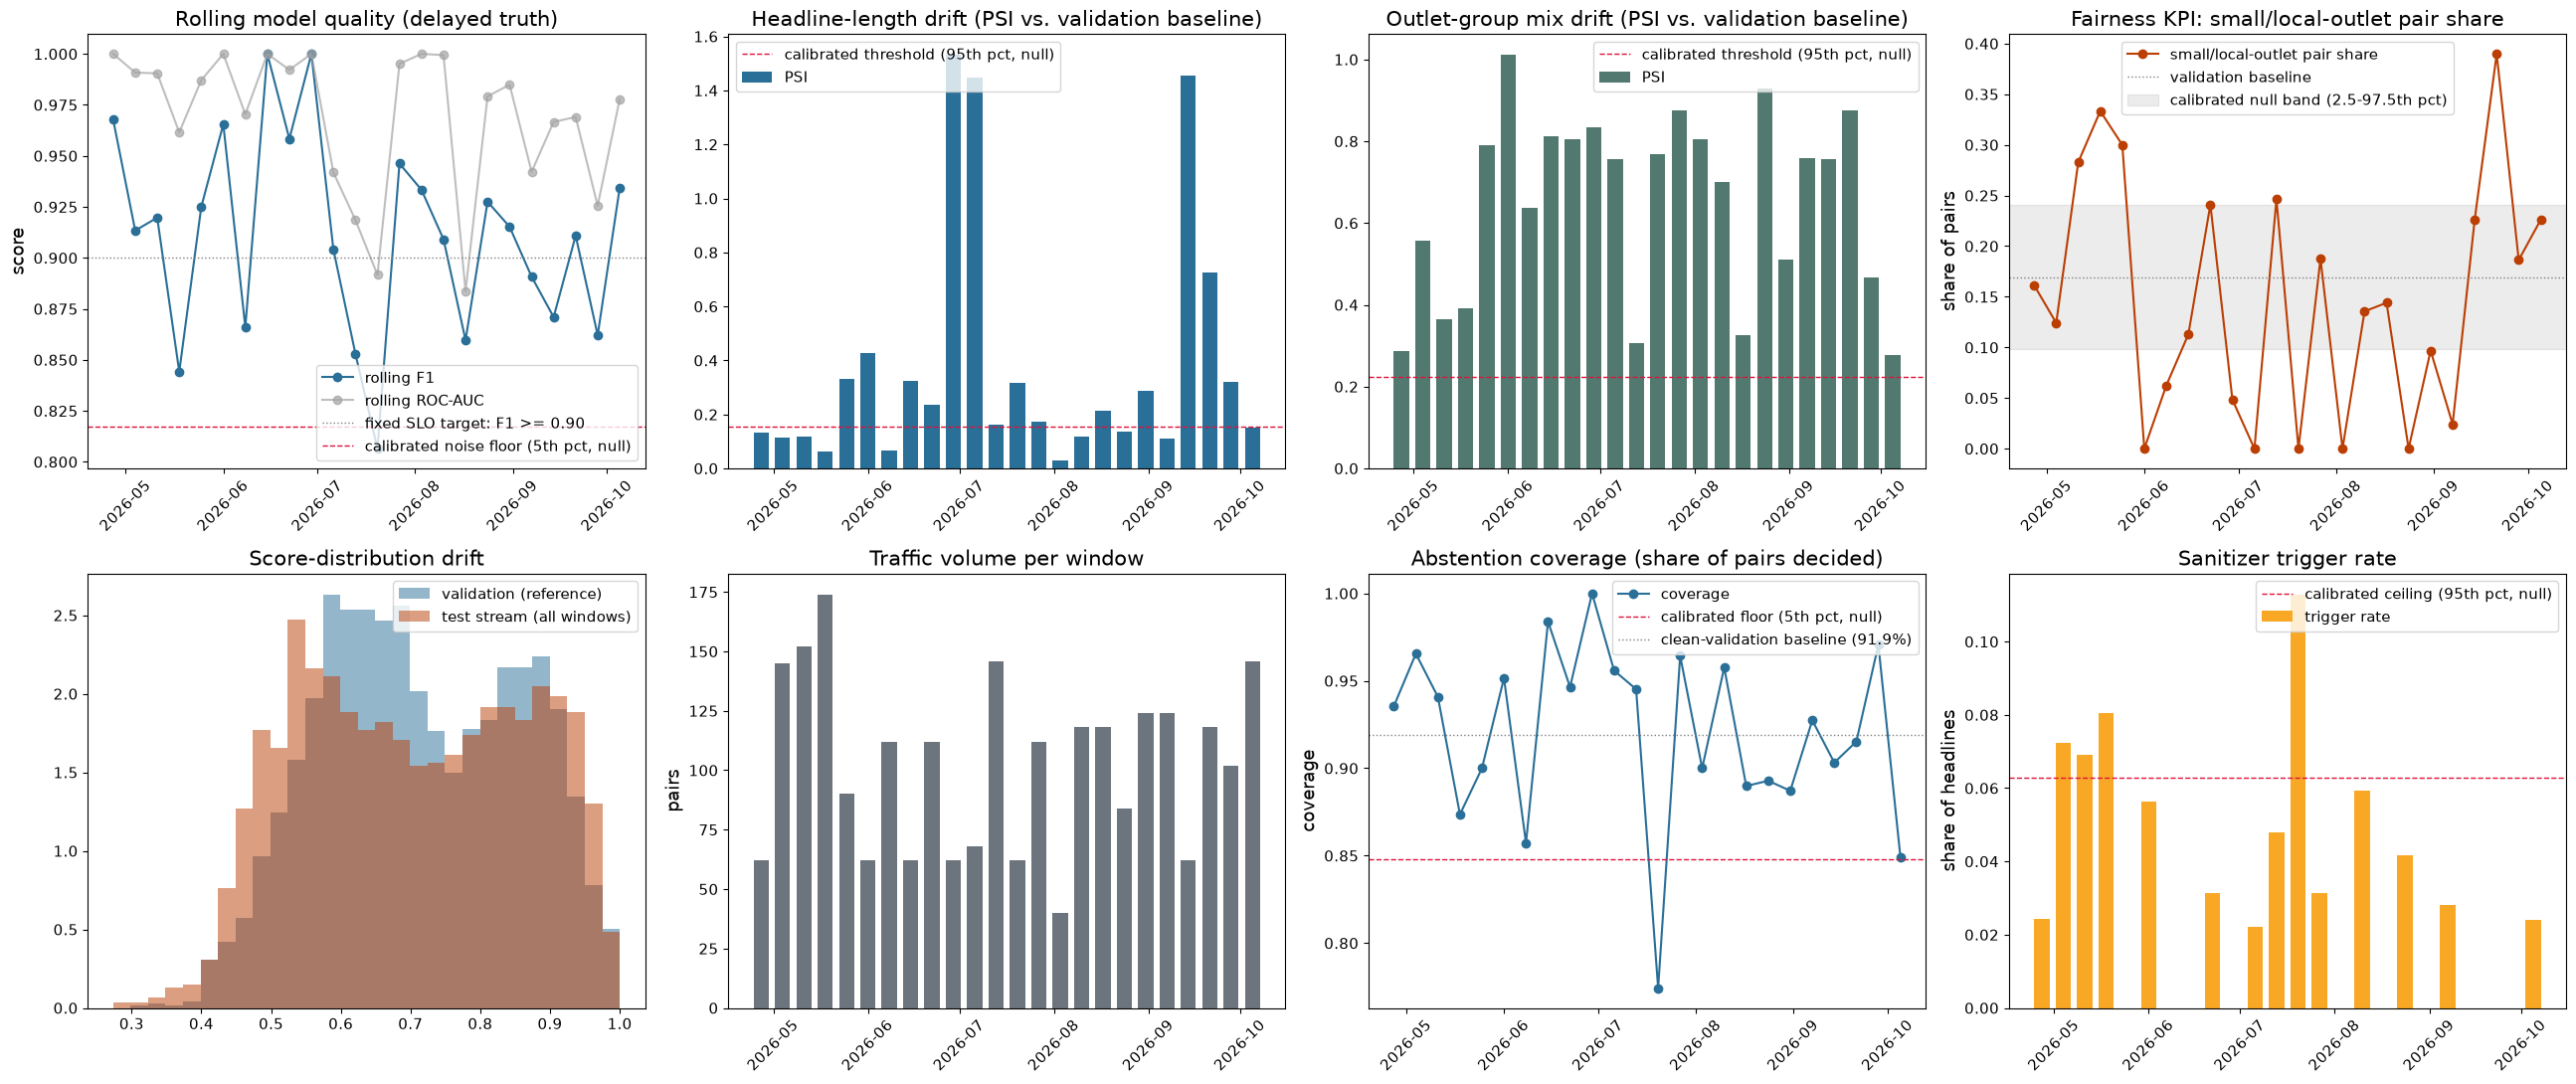

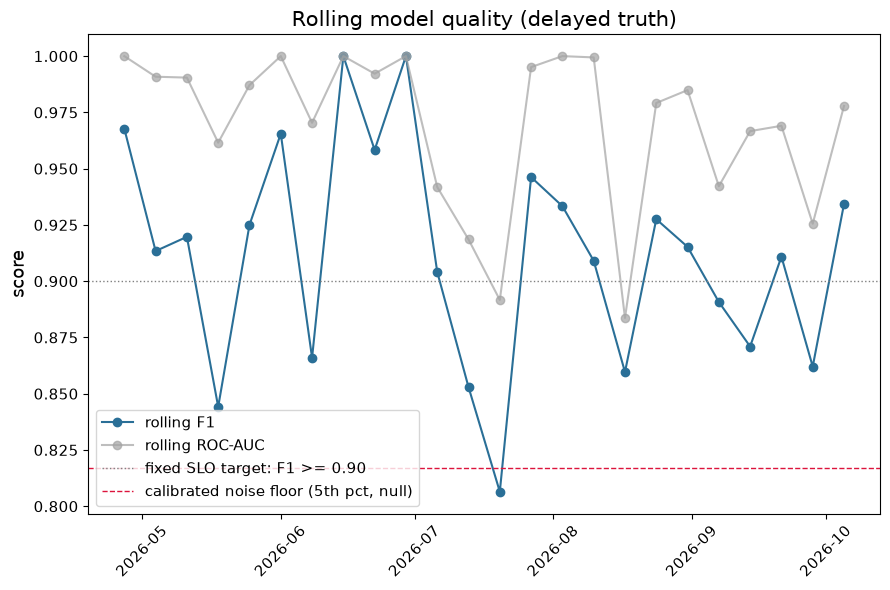

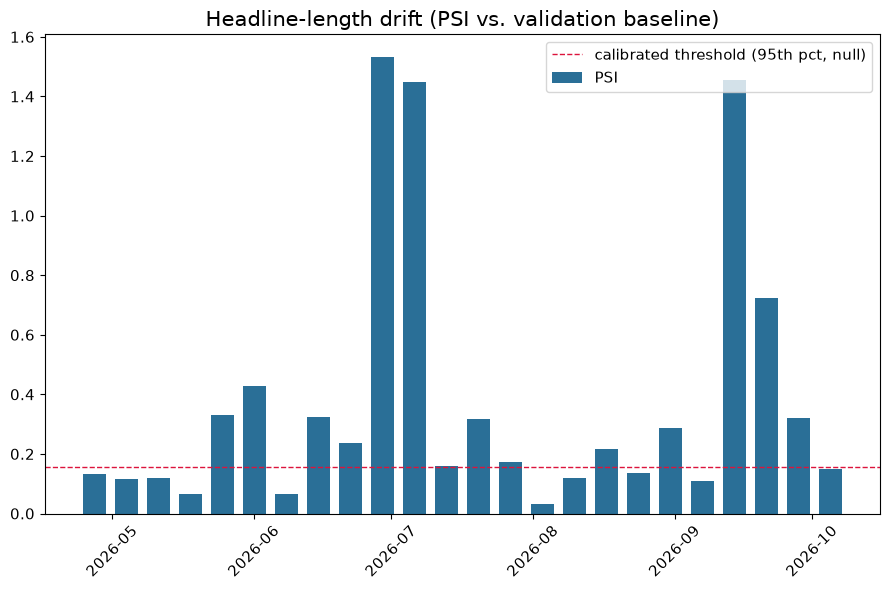

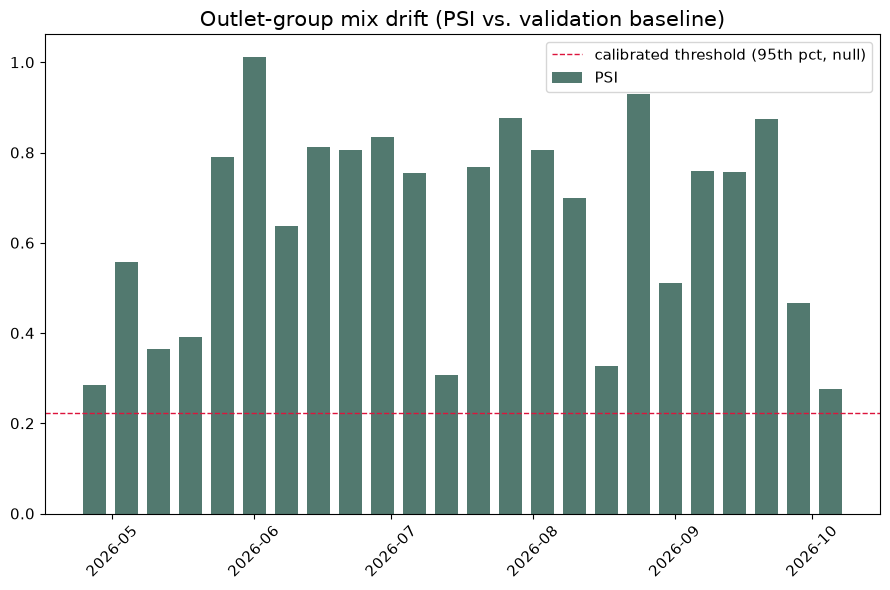

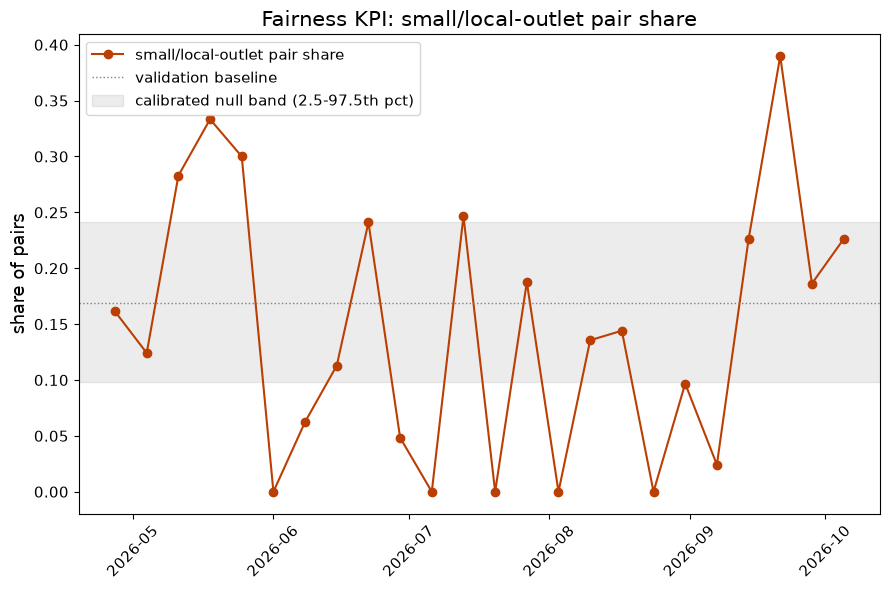

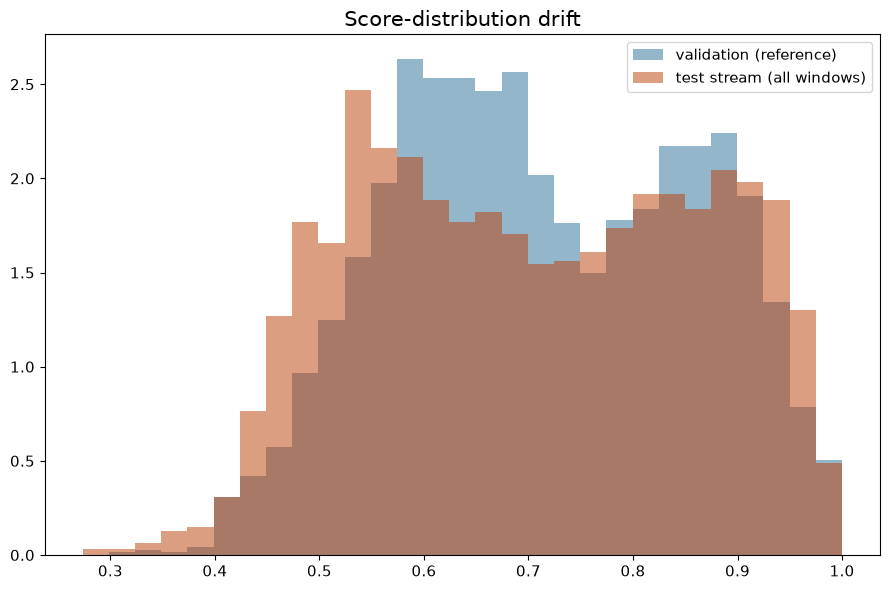

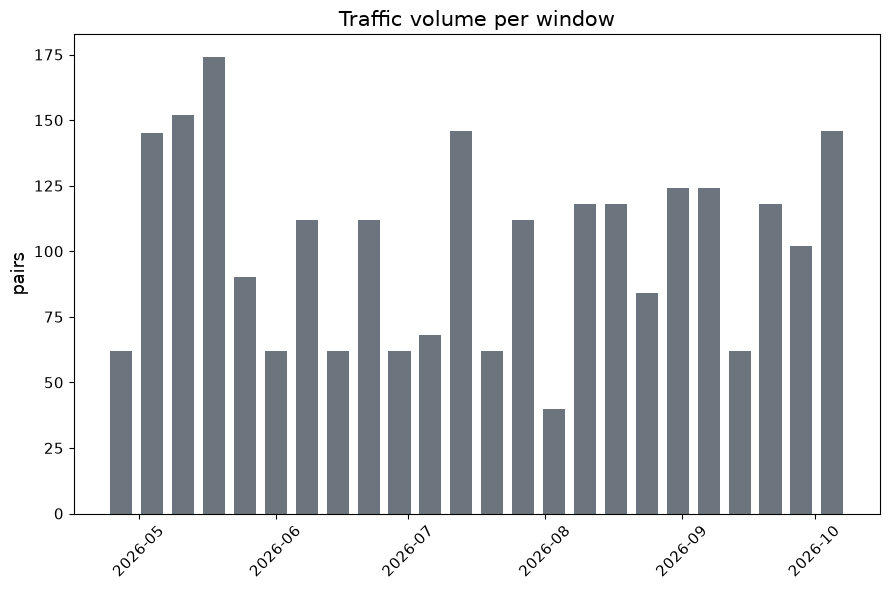

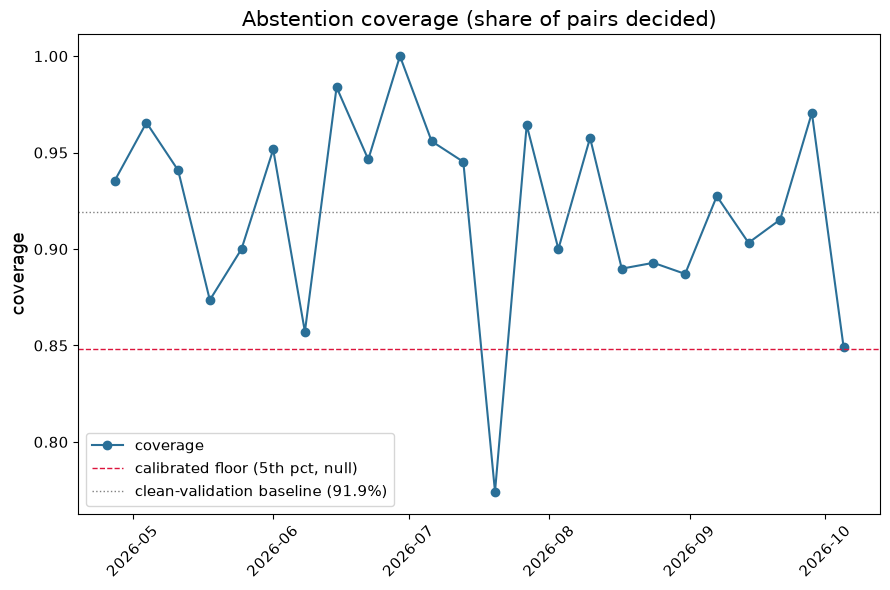

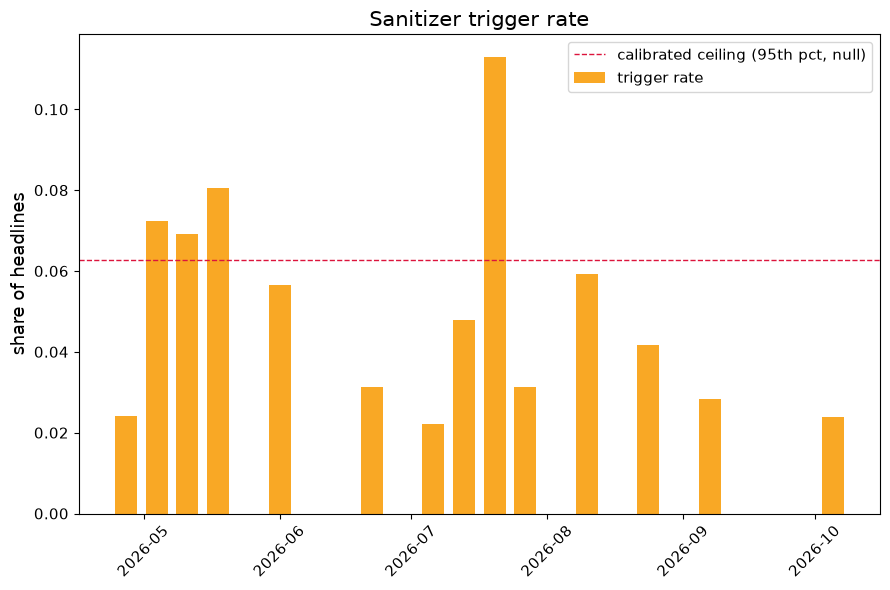

saved:
  outputs\milestone3\adaptation
  outputs\milestone3\alerts_by_window.csv
  outputs\milestone3\attack_entity_stuffing.csv
  outputs\milestone3\attack_gradient.csv
  outputs\milestone3\attack_greedy_summary.csv
  outputs\milestone3\attack_greedy_tfidf.csv
  outputs\milestone3\attack_greedy_v1.csv
  outputs\milestone3\attack_greedy_v1_san.csv
  outputs\milestone3\attack_greedy_v2_san.csv
  outputs\milestone3\calibrated_thresholds.csv
  outputs\milestone3\calibration_ece.csv
  outputs\milestone3\clean_metrics.csv
  outputs\milestone3\coverage_by_window.csv
  outputs\milestone3\drift_by_window.csv
  outputs\milestone3\efficiency.json
  outputs\milestone3\failure_candidates.csv
  outputs\milestone3\failure_table.csv
  outputs\milestone3\figures
  outputs\milestone3\grouping_under_corruption.csv
  outputs\milestone3\latency.csv
  outputs\milestone3\m2_consistency.csv
  outputs\milestone3\m2_reference.csv
  outputs\milestone3\model_size.csv
  outputs\milestone3\monitoring_dashboard.png

In [14]:
out_dir = Path("outputs/milestone3")
out_dir.mkdir(parents=True, exist_ok=True)

plot_dashboard(rolling, drift, reference, reference_scores, stream_scores, thresholds,
               out_dir / "monitoring_dashboard.png", coverage=coverage_tbl, sanitizer=sanitizer_tbl)

panel_paths = save_individual_panels(rolling, drift, reference, reference_scores, stream_scores, thresholds,
                                      out_dir / "panels", coverage=coverage_tbl, sanitizer=sanitizer_tbl)

rolling.to_csv(out_dir / "rolling_metrics.csv", index=False)
drift.to_csv(out_dir / "drift_by_window.csv", index=False)
alerts.to_csv(out_dir / "alerts_by_window.csv", index=False)
coverage_tbl.to_csv(out_dir / "coverage_by_window.csv", index=False)
sanitizer_tbl.to_csv(out_dir / "sanitizer_rate_by_window.csv", index=False)
pd.DataFrame([thresholds_display]).to_csv(out_dir / "calibrated_thresholds.csv", index=False)

print("saved:")
for f in sorted(out_dir.glob("*")):
    print(" ", f)
print("individual panels:")
for f in panel_paths:
    print(" ", f)